# Projet DiaCare Analytics : prédire le niveau de polymédication d'un patient diabétique

## Sommaire
| Partie | Contenu | Phase CRISP-DM |
|---|---|---|
| **Introduction** | Objectifs, critères de réussite | 1. Compréhension du métier |
| **Partie 1** | Chargement, nettoyage, visualisation | 2. Compréhension des données |
| **Partie 2** | Découpage, cible, encodage, normalisation | 3. Préparation des données |
| **Partie 3** | Sélection des variables (corrélation, ANOVA, ACP) | 3. Préparation des données |
| **Partie 4** | **Version A** : modèle « à l'admission » | 4. Modélisation + 5. Évaluation |
| **Partie 5** | **Version B** : modèle « après le séjour » | 4. Modélisation + 5. Évaluation |
| **Partie 6** | Le déséquilibre des classes et SMOTE | 4. Modélisation |
| **Partie 7** | **Comparaison A contre B** | 5. Évaluation |
| **Partie 8** | Évaluation finale et décision | 5. Évaluation |

*(La phase 6 « Déploiement » viendra après ce notebook.)*

---

## Les objectifs

**Objectif métier (le « pourquoi ») :** la pharmacie de l'hôpital ne peut pas relire toutes les ordonnances. On veut lui dire quels patients diabétiques recevront **beaucoup de médicaments**, car ce sont eux qui risquent le plus d'erreurs et d'interactions entre médicaments. Elle les vérifiera en premier.

**Objectif data science (le « comment ») :** classification supervisée à **3 classes**. Le modèle devine `polymed_group` : 0 = faible, 1 = moyenne, 2 = élevée.

**Critères de réussite :**
- **Accuracy ≥ 60 %** sur le test (critère de la prof)
- une bonne **précision** et un bon **rappel** (surtout pour la classe « élevée »)
- un modèle qui **n'apprend pas par cœur** (pas de sur-apprentissage)

## Comment est construite la cible ?
`num_medications` est un nombre (3, 12, 25, 40...). On ne peut pas faire une classification avec un nombre. On met donc les patients en file, du moins de médicaments au plus, puis on coupe la file en **3 parts égales** : 1er tiers = faible (0), 2e tiers = moyenne (1), 3e tiers = élevée (2).

## Les deux versions du modèle
| | Version A | Version B |
|---|---|---|
| Nom | « À l'admission » | « Après le séjour » |
| Informations utilisées | Seulement ce qu'on sait tôt | + durée du séjour + nombre d'analyses de labo |
| Utile pour | Prévenir la pharmacie dès l'arrivée | Contrôler les prescriptions à la fin du séjour |

# PARTIE 1 : Chargement et nettoyage
*(CRISP-DM : phase 2, compréhension des données)*

## 1.1 Les outils (imports)
On charge toutes les bibliothèques d'un seul coup, pour ne plus y penser ensuite.

In [ ]:
import warnings, re
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             classification_report, ConfusionMatrixDisplay)
from xgboost import XGBClassifier

try:
    from imblearn.over_sampling import SMOTE
    from imblearn.pipeline import Pipeline as ImbPipeline
except ImportError:                      # si imblearn n'est pas installé (Colab : le plus souvent il l'est)
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "imbalanced-learn"])
    from imblearn.over_sampling import SMOTE
    from imblearn.pipeline import Pipeline as ImbPipeline

sns.set_theme(style="whitegrid")

## 1.2 Charger `df_clean`
Lance la cellule. Sur Google Colab, clique sur « Choisir des fichiers » et sélectionne `df_clean.csv`.

`keep_default_na=False` est important : sans lui, pandas transforme le texte « None » (test non fait) en valeur manquante.

In [ ]:
try:                                     # sur Google Colab : on envoie le fichier
    from google.colab import files
    files.upload()
except ImportError:                      # ailleurs : le fichier doit être dans le même dossier
    pass

df = pd.read_csv("df_clean.csv", keep_default_na=False)
print(df.shape)
df.head()

Saving df_clean.csv to df_clean.csv
(69970, 43)


,race,gender,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,medical_specialty,num_lab_procedures,num_procedures,...,troglitazone,tolazamide,insulin,glyburide-metformin,glipizide-metformin,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,Caucasian,Female,[80-90),2,1,4,13,Unknown,68,2,...,No,No,Steady,No,No,No,No,Ch,Yes,NO
1,Caucasian,Female,[90-100),3,3,4,12,InternalMedicine,33,3,...,No,No,Steady,No,No,No,No,Ch,Yes,NO
2,Caucasian,Male,[40-50),1,1,7,1,Unknown,51,0,...,No,No,Steady,No,No,No,No,Ch,Yes,NO
3,AfricanAmerican,Female,[40-50),1,1,7,9,Unknown,47,2,...,No,No,Steady,No,No,No,No,No,Yes,>30
4,Caucasian,Male,[50-60),2,1,2,3,Unknown,31,6,...,No,No,Steady,No,No,No,No,No,Yes,>30


## 1.3 Doublons et valeurs manquantes
**Pourquoi ?** Un doublon compterait deux fois le même patient. Une valeur manquante fait planter beaucoup de modèles.

In [ ]:
print("Doublons :", df.duplicated().sum())
df = df.drop_duplicates()
print("Valeurs manquantes :", df.isnull().sum().sum())
print("Tests non faits (A1Cresult) :", (df['A1Cresult']=='None').sum())

Doublons : 0
Valeurs manquantes : 0
Tests non faits (A1Cresult) : 57125


« None » veut dire « test non fait », ce n'est pas une valeur manquante. On le renomme pour que ce soit clair.

In [ ]:
df['A1Cresult'] = df['A1Cresult'].replace('None','Non_teste')
df['max_glu_serum'] = df['max_glu_serum'].replace('None','Non_teste')

## 1.4 Visualisation (histogrammes)
**Pourquoi ?** Pour voir à quoi ressemblent les données avant de les toucher.

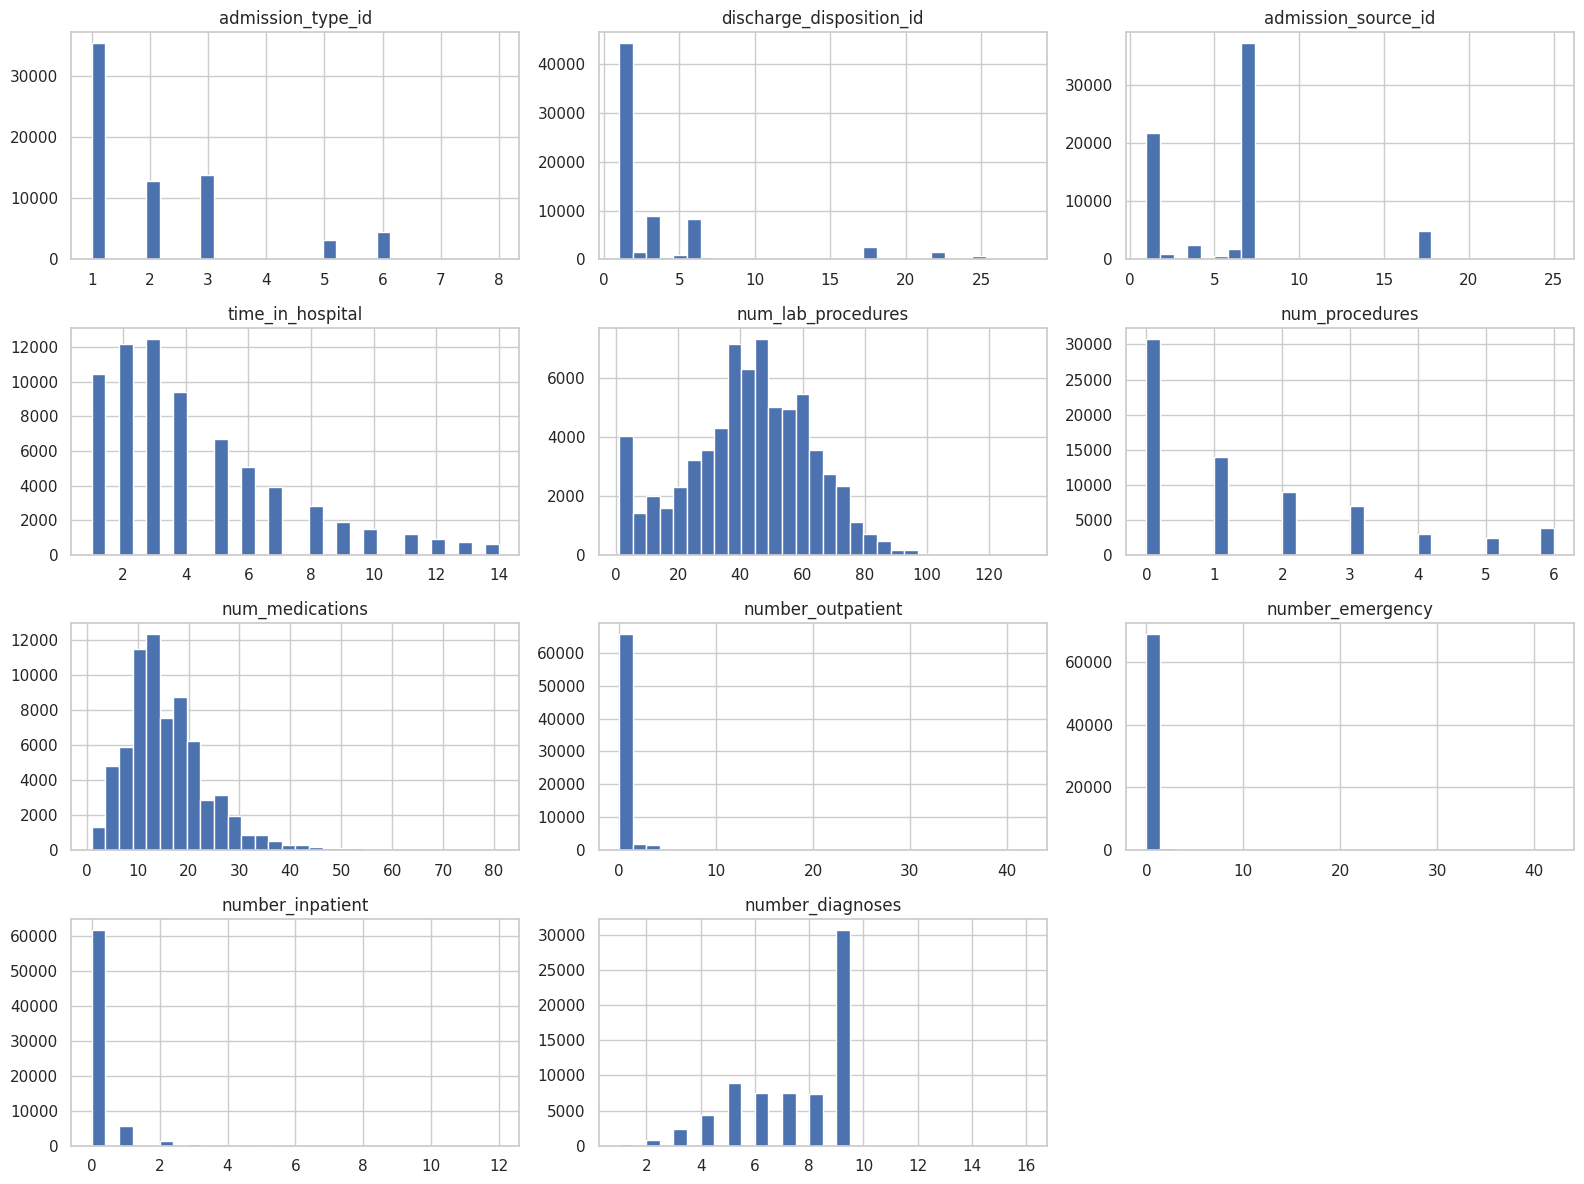

In [ ]:
num_cols = df.select_dtypes(include='number').columns.tolist()
df[num_cols].hist(figsize=(16,12), bins=30)
plt.tight_layout(); plt.show()

**1. `admission_type_id`, `discharge_disposition_id`, `admission_source_id`**
- On voit : quelques barres très hautes et beaucoup de barres minuscules.
- Ça veut dire : ce ne sont pas de vrais nombres mais des **codes de catégories**. Le code 7 n'est pas « plus grand » que le code 1.
- On fera : les transformer en texte puis en one-hot, pour que le modèle ne les prenne pas pour des quantités.

**2. `time_in_hospital`, `num_lab_procedures`, `num_procedures`, `num_medications`, `number_outpatient`, `number_emergency`**
- `time_in_hospital` : la plupart des séjours durent 1 à 4 jours, avec une longue queue jusqu'à 14.
- `num_lab_procedures` : une cloche autour de 40, avec un pic près de 0 (patients sans analyses).
- `num_procedures` : la majorité des patients ont 0 acte.
- `num_medications` (notre cible de départ) : un pic vers 12-13 médicaments et une longue queue jusqu'à 80.
- `number_outpatient`, `number_emergency` : presque tout le monde est à 0.
- Ça veut dire : les données sont **asymétriques** (beaucoup de petites valeurs, quelques énormes). C'est pour ça qu'on traite les valeurs extrêmes.

**3. `number_inpatient` et `number_diagnoses`**
- `number_diagnoses` : une barre énorme à 9. Ça ressemble à un plafond de saisie : beaucoup de patients sont « bloqués » à 9. La variable reste utile mais moins fine qu'elle n'en a l'air.

## 1.5 Boxplot de la cible de départ
**Pourquoi ?** Pour repérer les valeurs bizarres.

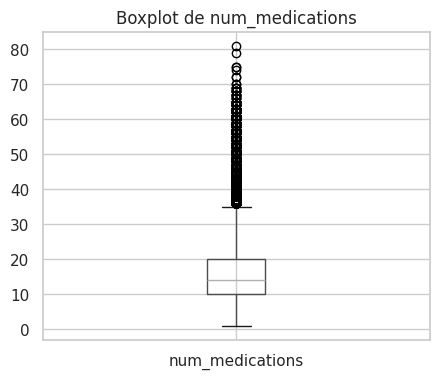

In [ ]:
df.boxplot(column='num_medications', figsize=(5,4))
plt.title("Boxplot de num_medications"); plt.show()

- On voit : la boîte va d'environ 10 à 20 médicaments, avec une médiane vers 14. Au-dessus de 35, une rangée de points isolés (les outliers) jusqu'à 80.
- Ça veut dire : ces patients sont très éloignés de la majorité. Ce ne sont probablement pas des erreurs, mais ils tireraient les calculs.
- On fera : ramener ces valeurs à une limite (le 99e percentile), **sans supprimer de patient**. Cette étape est faite en 2.2, juste après le découpage train/test.

# PARTIE 2 : Préparation des données
*(CRISP-DM : phase 3, préparation des données)*

> ## ⚠️ Changement important par rapport à l'ancienne version
> Avant, tu calculais la limite des valeurs extrêmes et les seuils de la cible **sur tous les patients**, puis tu coupais en train/test. C'était une **petite fuite** : le test avait déjà influencé la préparation.
>
> Maintenant on coupe **d'abord** en train/test, puis on calcule tout (limite, seuils, scaler, top spécialités) **sur le train seulement** et on applique ensuite au test. C'est la bonne méthode.

## 2.1 Découpage train / test (80 % / 20 %)
**Pourquoi en premier ?** Le **test** joue le rôle de « patients futurs qu'on n'a jamais vus ». Rien de ce qu'on calcule ne doit venir de lui.

On ne peut pas utiliser `stratify` ici, car la cible n'existe pas encore. Ce n'est pas grave : on vérifiera en 2.5 que les classes restent équilibrées.

In [ ]:
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)
train_df = train_df.copy()
test_df  = test_df.copy()
print("Train :", train_df.shape, "  |  Test :", test_df.shape)

Train : (55976, 43)   |  Test : (13994, 43)


## 2.2 Valeurs extrêmes
On ne supprime aucun patient : on ramène les valeurs très grandes au **99e percentile**.
**Le plafond est calculé sur le train**, puis appliqué aux deux parties.

In [ ]:
cap = train_df['num_medications'].quantile(0.99)
print("Plafond (calculé sur le train) :", cap)
train_df['num_medications'] = train_df['num_medications'].clip(upper=cap)
test_df['num_medications']  = test_df['num_medications'].clip(upper=cap)

Plafond (calculé sur le train) : 44.0


## 2.3 Création de la cible `polymed_group`
On coupe `num_medications` en 3 groupes de même taille (faible, moyenne, élevée).
**Les deux seuils sont calculés sur le train** (au tiers et aux deux tiers des patients), puis appliqués au test avec `pd.cut`.

In [ ]:
seuil1, seuil2 = train_df['num_medications'].quantile([1/3, 2/3]).values
print("Seuils (calculés sur le train) :", seuil1, "et", seuil2)

def creer_cible(serie):
    return pd.cut(serie, bins=[-np.inf, seuil1, seuil2, np.inf], labels=[0, 1, 2]).astype(int)

train_df['polymed_group'] = creer_cible(train_df['num_medications'])
test_df['polymed_group']  = creer_cible(test_df['num_medications'])

Seuils (calculés sur le train) : 11.0 et 17.0


- Groupe 0 (**faible**) : jusqu'à `seuil1` médicaments.
- Groupe 1 (**moyenne**) : entre `seuil1` et `seuil2`.
- Groupe 2 (**élevée**) : au-dessus de `seuil2`.

## 2.4 Pourquoi cette cible a-t-elle un sens ?
On vérifie que les patients à forte polymédication restent plus longtemps et reviennent plus souvent avant 30 jours. (On regarde seulement le **train**.)

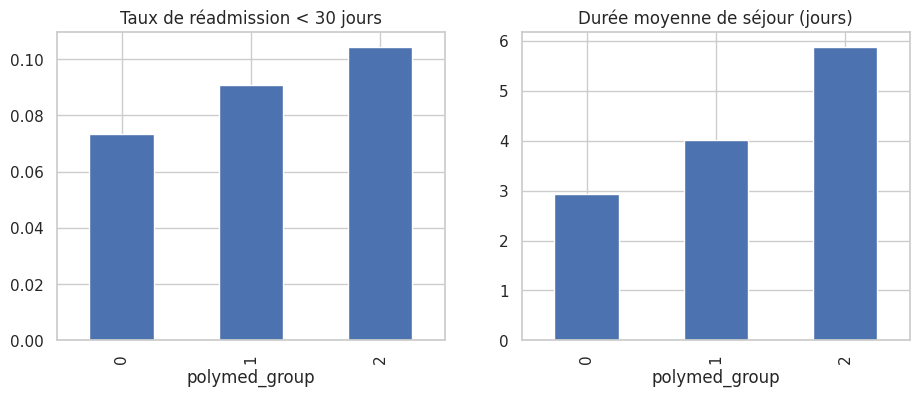

In [ ]:
tmp = train_df.assign(readmit_30=(train_df['readmitted']=='<30').astype(int))
fig, ax = plt.subplots(1, 2, figsize=(11,4))
tmp.groupby('polymed_group')['readmit_30'].mean().plot(kind='bar', ax=ax[0], title="Taux de réadmission < 30 jours")
tmp.groupby('polymed_group')['time_in_hospital'].mean().plot(kind='bar', ax=ax[1], title="Durée moyenne de séjour (jours)")
plt.show()

- Gauche : le taux de réadmission avant 30 jours monte avec le niveau de polymédication.
- Droite : la durée moyenne de séjour monte aussi (environ 3 jours, puis 4, puis 6).
- Ça veut dire : plus un patient prend de médicaments, plus il reste longtemps. La cible a donc un vrai sens médical.
- **Attention :** c'est une association, pas une cause. Un patient plus malade a plus de médicaments **et** reste plus longtemps.
- **Conséquence importante :** `time_in_hospital` est très lié à la cible. C'est exactement la différence entre les versions A et B (voir Partie 5).

## 2.5 Les classes sont-elles équilibrées ?
**Pourquoi c'est important :** la prof pense que la base est déséquilibrée. Vérifions **pour notre cible** (et pas pour `readmitted`).

            Train    Test
0 faible   33.7 %  33.3 %
1 moyenne  33.0 %  33.2 %
2 élevée   33.3 %  33.6 %


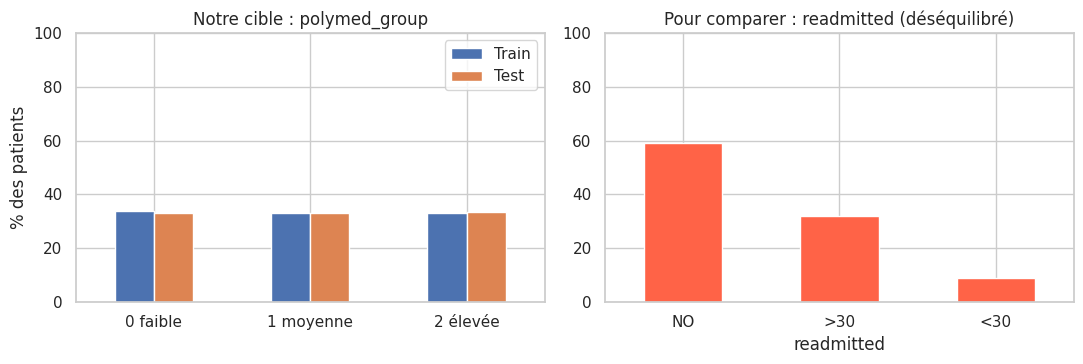

In [ ]:
prop = pd.DataFrame({
    "Train": train_df['polymed_group'].value_counts(normalize=True).sort_index(),
    "Test":  test_df['polymed_group'].value_counts(normalize=True).sort_index()})
prop.index = ["0 faible", "1 moyenne", "2 élevée"]
print((prop*100).round(1).astype(str) + " %")

fig, ax = plt.subplots(1, 2, figsize=(11,3.8))
(prop*100).plot(kind='bar', ax=ax[0], rot=0, title="Notre cible : polymed_group")
ax[0].set_ylim(0, 100); ax[0].set_ylabel("% des patients")
(train_df['readmitted'].value_counts(normalize=True)*100).plot(kind='bar', ax=ax[1], rot=0, color="tomato",
                                                              title="Pour comparer : readmitted (déséquilibré)")
ax[1].set_ylim(0, 100)
plt.tight_layout(); plt.show()

- On voit : notre cible (à gauche) a **3 barres presque égales** (environ 33 % chacune), au train comme au test.
- À droite, pour comparer : la colonne `readmitted`, elle, est **vraiment déséquilibrée** (la classe « <30 » est rare). C'est probablement ce que la prof a en tête, mais ce n'est **pas notre cible**.
- Ça veut dire : nos classes sont **équilibrées par construction** (on a coupé en 3 parts égales). Un modèle qui répond au hasard aurait environ 33 %.
- On fera quand même un **test SMOTE** (Partie 6) pour répondre proprement à la prof, avec des chiffres.

## 2.6 Regrouper les colonnes trop détaillées
`diag_1/2/3` ont environ 700 valeurs : on les regroupe en **familles de maladies**. `medical_specialty` a 71 valeurs : on garde les **10 plus fréquentes du train** et on met le reste dans « Autre ». Sans ça, l'encodage créerait des milliers de colonnes.

In [ ]:
def famille(code):
    c = str(code)
    if c.startswith('250'): return 'Diabete'
    if c[0] in 'VE': return 'Autre'
    try: n = float(c)
    except: return 'Autre'
    if 390<=n<=459 or n==785: return 'Circulatoire'
    if 460<=n<=519 or n==786: return 'Respiratoire'
    if 520<=n<=579 or n==787: return 'Digestif'
    if 800<=n<=999: return 'Lesions'
    if 710<=n<=739: return 'Musculo'
    if 580<=n<=629 or n==788: return 'Genito_urinaire'
    if 140<=n<=239: return 'Tumeurs'
    return 'Autre'

top_specialites = train_df['medical_specialty'].value_counts().nlargest(10).index   # choisies sur le train
for d in (train_df, test_df):
    for c in ['diag_1','diag_2','diag_3']:
        d[c] = d[c].apply(famille)
    d['medical_specialty'] = d['medical_specialty'].where(d['medical_specialty'].isin(top_specialites), 'Autre')

## 2.7 Retirer les colonnes qui donnent la réponse (fuite d'information)
**Le danger :** si une colonne contient déjà la réponse, le modèle fait 100 % mais ne sert à rien en vrai.

On retire :
- `num_medications` : c'est la cible elle-même
- les **20 colonnes de médicaments** du diabète : elles sont une partie du nombre de médicaments
- `readmitted` : elle vient après le séjour
- `discharge_disposition_id` : la destination de sortie, connue à la fin

On **garde** pour l'instant `time_in_hospital` et `num_lab_procedures` : elles servent à la version B. La version A les retirera à l'étape 3.

In [ ]:
med_cols = ['metformin','repaglinide','nateglinide','chlorpropamide','glimepiride','acetohexamide','glipizide',
            'glyburide','tolbutamide','pioglitazone','rosiglitazone','acarbose','miglitol','troglitazone','tolazamide',
            'insulin','glyburide-metformin','glipizide-metformin','metformin-rosiglitazone','metformin-pioglitazone']
a_retirer = ['polymed_group','num_medications','readmitted','discharge_disposition_id'] + med_cols

y_train = train_df['polymed_group']
y_test  = test_df['polymed_group']
X_train = train_df.drop(columns=a_retirer)
X_test  = test_df.drop(columns=a_retirer)
print(X_train.shape, X_test.shape)

(55976, 20) (13994, 20)


## 2.8 Encodage
Les modèles ne comprennent que les nombres :
- colonnes à 2 valeurs → 0/1
- autres colonnes de texte → **one-hot** (une colonne 0/1 par valeur)

On encode le train, puis on donne **exactement les mêmes colonnes** au test (`reindex`). On retire aussi les colonnes constantes (calculé sur le train).

**Nettoyage des noms :** XGBoost refuse les caractères `[`, `]` et `<` dans les noms de colonnes (ex : `age_[10-20)`). On les remplace par `_`.

In [ ]:
def encoder(X):
    X = X.copy()
    X['gender']      = (X['gender']=='Male').astype(int)
    X['change']      = (X['change']=='Ch').astype(int)
    X['diabetesMed'] = (X['diabetesMed']=='Yes').astype(int)
    for c in ['admission_type_id','admission_source_id']:      # ce sont des codes, pas des quantités
        X[c] = X[c].astype(str)
    return pd.get_dummies(X, drop_first=True).astype(int)

X_train = encoder(X_train)
X_test  = encoder(X_test).reindex(columns=X_train.columns, fill_value=0)

X_train = X_train.loc[:, X_train.std() > 0]        # retire les colonnes constantes
X_test  = X_test[X_train.columns]

noms = [re.sub(r'[\[\]<>,:"{}]', '_', c) for c in X_train.columns]
X_train.columns = noms
X_test.columns  = noms
print(X_train.shape, X_test.shape)

(55976, 86) (13994, 86)


## 2.9 Normalisation (StandardScaler)
Elle met les nombres continus à la même échelle. Sinon « nombre de diagnostics » (petit) et « nombre d'analyses » (grand) ne seraient pas comparables.

**L'échelle est apprise sur le train seulement**, puis appliquée au test. Si on regardait le test pendant l'apprentissage, ce serait de la triche.

In [ ]:
cont = ['num_procedures','number_outpatient','number_emergency','number_inpatient','number_diagnoses',
        'time_in_hospital','num_lab_procedures']
scaler = StandardScaler()
X_train[cont] = scaler.fit_transform(X_train[cont])
X_test[cont]  = scaler.transform(X_test[cont])
print("Variables disponibles au total :", X_train.shape[1])

Variables disponibles au total : 86


# PARTIE 3 : Sélection des variables
*(CRISP-DM : phase 3, préparation des données)*

On sépare maintenant les deux versions :

| | Variables |
|---|---|
| **Version A** (admission) | toutes **sauf** `time_in_hospital` et `num_lab_procedures`, puis les 20 meilleures par ANOVA |
| **Version B** (après séjour) | **toutes** les variables, y compris ces deux-là (voir Partie 5) |

In [ ]:
vars_fin_sejour = ['time_in_hospital', 'num_lab_procedures']
vars_admission  = [c for c in X_train.columns if c not in vars_fin_sejour]
print("Variables version A (avant sélection) :", len(vars_admission))
print("Variables version B (toutes)          :", X_train.shape[1])

Variables version A (avant sélection) : 84
Variables version B (toutes)          : 86


## 3.1 Matrice de corrélation
Elle sert à voir quelles variables se ressemblent.

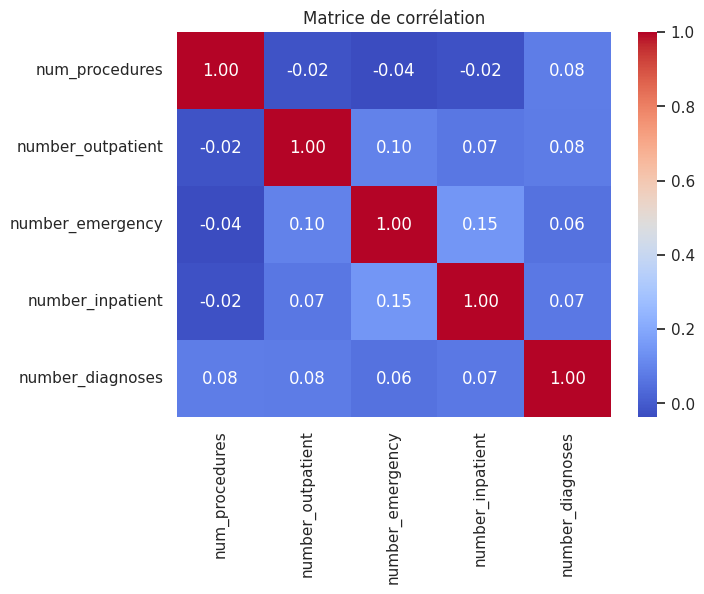

In [ ]:
cont_A = ['num_procedures','number_outpatient','number_emergency','number_inpatient','number_diagnoses']
plt.figure(figsize=(7,5))
sns.heatmap(X_train[cont_A].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title("Matrice de corrélation"); plt.show()

- On voit : presque tout est proche de 0. La plus forte valeur est 0,15 (entre `number_emergency` et `number_inpatient`).
- Ça veut dire : ces variables sont presque indépendantes, donc il n'y a pas de doublon à supprimer. Le seuil d'alerte serait autour de 0,8.
- Petite lecture : les patients qui vont souvent aux urgences sont un peu plus souvent hospitalisés.

## 3.2 ANOVA (choisir les 20 meilleures variables de la version A)
L'ANOVA mesure si une variable a des moyennes **différentes entre les classes** de la cible. Plus le score F est élevé, plus la variable aide à séparer les 3 groupes.

On utilise l'ANOVA et pas la corrélation de Pearson, car notre cible est une **catégorie** à 3 valeurs. Le score est calculé **sur le train seulement**.

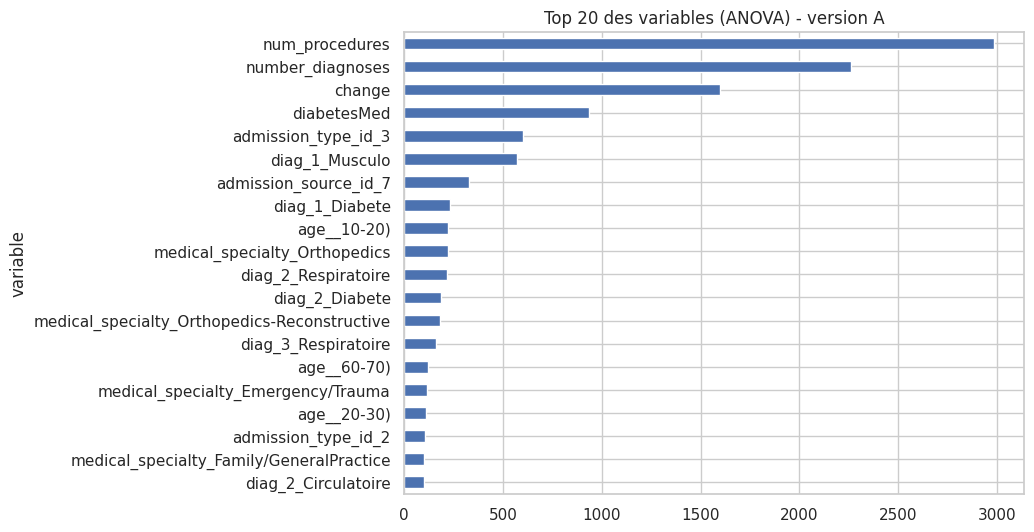

['num_procedures', 'number_diagnoses', 'change', 'diabetesMed', 'age__10-20)', 'age__20-30)', 'age__60-70)', 'admission_type_id_2', 'admission_type_id_3', 'admission_source_id_7', 'medical_specialty_Emergency/Trauma', 'medical_specialty_Family/GeneralPractice', 'medical_specialty_Orthopedics', 'medical_specialty_Orthopedics-Reconstructive', 'diag_1_Diabete', 'diag_1_Musculo', 'diag_2_Circulatoire', 'diag_2_Diabete', 'diag_2_Respiratoire', 'diag_3_Respiratoire']


In [ ]:
sel = SelectKBest(f_classif, k=20).fit(X_train[vars_admission], y_train)
scores = pd.DataFrame({'variable': vars_admission, 'score': sel.scores_}).sort_values('score', ascending=False)
scores.head(20).plot(kind='barh', x='variable', y='score', figsize=(8,6), legend=False).invert_yaxis()
plt.title("Top 20 des variables (ANOVA) - version A"); plt.show()

feat_A = list(X_train[vars_admission].columns[sel.get_support()])
print(feat_A)

- On voit : `num_procedures` est en tête, puis `number_diagnoses`, `change` et `diabetesMed`. Les autres sont bien plus bas.
- Ça veut dire : plus d'actes médicaux et plus de diagnostics donnent plus de médicaments. Les spécialités orthopédiques correspondent souvent à des patients opérés.
- On garde ces 20 variables pour la version A.

## 3.3 ACP (pour comprendre, pas pour modéliser)
L'ACP résume les variables en moins de composantes. La courbe montre combien de composantes il faut pour garder 90 % de l'information.

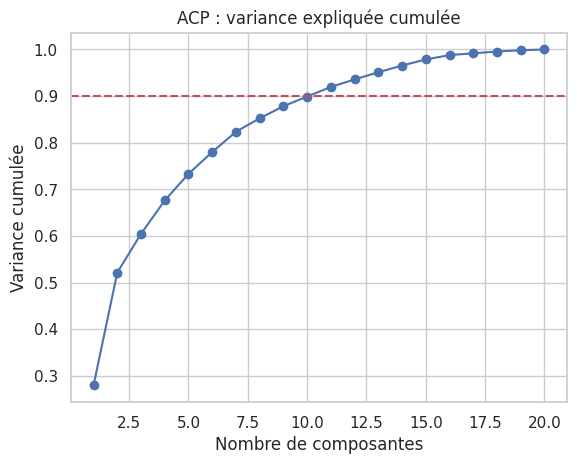

1re composante : 28 %
Composantes pour 90 % : 11


In [ ]:
pca = PCA().fit(X_train[feat_A])
cum = np.cumsum(pca.explained_variance_ratio_)
plt.plot(range(1, len(cum)+1), cum, marker='o')
plt.axhline(0.9, color='r', linestyle='--'); plt.xlabel("Nombre de composantes"); plt.ylabel("Variance cumulée")
plt.title("ACP : variance expliquée cumulée"); plt.show()
print("1re composante :", round(pca.explained_variance_ratio_[0]*100), "%")
print("Composantes pour 90 % :", int(np.argmax(cum >= 0.9)) + 1)

- On voit : la 1re composante explique seulement environ **28 %** de l'information, et il faut **11 composantes** pour atteindre 90 % (le programme l'affiche).
- Ça veut dire : l'information est répartie sur beaucoup de composantes, car les variables sont peu corrélées entre elles. Dans le cours, l'exemple avait PC1 + PC2 = 98 % parce que ses variables étaient très liées. Ici on ne peut résumer que de moitié (20 → 11).
- **Décision :** on garde les 20 variables de l'ANOVA, plus faciles à interpréter. L'ACP fait perdre un peu d'information et d'interprétabilité.

## 3.4 Résultat : les jeux de données prêts

In [ ]:
X_train_A, X_test_A = X_train[feat_A], X_test[feat_A]     # version A : 20 variables
X_train_B, X_test_B = X_train, X_test                     # version B : toutes les variables

print("Version A :", X_train_A.shape, X_test_A.shape)
print("Version B :", X_train_B.shape, X_test_B.shape)
print("Valeurs manquantes :", X_train_A.isna().sum().sum(), "/", X_train_B.isna().sum().sum())

Version A : (55976, 20) (13994, 20)
Version B : (55976, 86) (13994, 86)
Valeurs manquantes : 0 / 0


# PARTIE 4 : Version A, le modèle « à l'admission »
*(CRISP-DM : phase 4 Modélisation + phase 5 Évaluation)*

**Ce qu'on fait :** on apprend à un modèle à deviner `polymed_group` avec les **20 variables de l'ANOVA** (`X_train_A`). Aucune information de fin de séjour n'est utilisée.

**Plan :**
1. Choisir le modèle et expliquer pourquoi
2. Préparer les outils d'évaluation
3. Vérifier que ce choix est utile (contre des modèles simples)
4. Régler le modèle
5. L'évaluer sur le test
6. Vérifier qu'il n'a pas appris par cœur
7. Comprendre ce qu'il utilise

## 4.1 Quel modèle choisir, et pourquoi ?

On ne teste pas tous les algorithmes au hasard : on **choisit** celui qui correspond à nos données et à notre cours.

**Ce qu'on sait de nos données :**
- 3 classes de même taille (voir 2.5)
- environ 56 000 patients d'entraînement, surtout des colonnes 0/1 (one-hot)
- les variables sont presque indépendantes entre elles (corrélations proches de 0)
- la cible est un nombre coupé en 3 : les patients proches des seuils (11-12 ou 17-18 médicaments) sont difficiles à classer

| Modèle | Choix | Pourquoi |
|---|---|---|
| Régression logistique | Référence seulement | Elle ne voit que des relations en ligne droite. Les variables peuvent se combiner (ex : famille de diagnostic et spécialité). |
| Arbre de décision | Non | Un seul arbre est instable et apprend vite par cœur (forte variance, cours Intro ML). |
| Random Forest (bagging) | Non | Stable, mais ses arbres sont indépendants : ils ne corrigent pas leurs erreurs. Le bagging réduit surtout la variance. |
| AdaBoost | Non | Il donne plus de poids aux patients mal classés. Ici, les patients proches des seuils sont mal classés par nature : il s'acharnerait sur eux (le boosting est sensible au bruit). |
| Gradient Boosting (scikit-learn), LightGBM | Non | Même principe que XGBoost, mais plus lent ou moins vu en cours. |
| **XGBoost** | **Choisi** | Boosting : réduit le biais **et** la variance. Il a de la régularisation intégrée contre le sur-apprentissage, il est rapide et très utilisé sur les données en tableau. |

### Comment XGBoost marche (simple)
1. Un petit arbre fait une première prédiction, il se trompe sur certains patients.
2. Un 2e petit arbre apprend à **corriger les erreurs** du 1er.
3. On recommence des centaines de fois et on additionne tous les petits arbres.

Le mot « gradient » veut dire : chaque arbre corrige dans la direction où l'erreur diminue le plus vite.

⚠️ Ce choix est fait par raisonnement. L'étape 4.3 le **vérifie** sur les données.

## 4.2 Préparer les outils d'évaluation
Pour ne pas recopier le même code pour A et pour B, on écrit une fois pour toutes deux petites fonctions :
- `evaluer(...)` : passe le modèle sur le **test** et range les résultats dans le dictionnaire `resultats`
- `intervalle_accuracy(...)` : donne une fourchette autour de l'accuracy (utile en Partie 7)

In [ ]:
noms_classes = ["faible", "moyenne", "élevée"]
resultats = {}          # on y range les résultats de A et de B pour les comparer plus tard

def evaluer(nom_version, modele, X_tr, X_te):
    # Passe le modèle sur le test (une seule fois) et affiche les résultats.
    y_pred = modele.predict(X_te)
    res = {
        "accuracy":         accuracy_score(y_test, y_pred),
        "precision_macro":  precision_score(y_test, y_pred, average='macro'),
        "rappel_macro":     recall_score(y_test, y_pred, average='macro'),
        "f1_macro":         f1_score(y_test, y_pred, average='macro'),
        "precision_elevee": precision_score(y_test, y_pred, labels=[2], average=None)[0],
        "rappel_elevee":    recall_score(y_test, y_pred, labels=[2], average=None)[0],
        "accuracy_train":   accuracy_score(y_train, modele.predict(X_tr)),
        "y_pred":           y_pred,
    }
    res["ecart"] = res["accuracy_train"] - res["accuracy"]
    resultats[nom_version] = res

    print(f"Accuracy : {res['accuracy']:.3f}   |   F1 macro : {res['f1_macro']:.3f}\n")
    print(classification_report(y_test, y_pred, target_names=noms_classes, digits=3))
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=noms_classes,
                                            normalize='true', values_format='.0%', cmap="Blues")
    plt.title(f"Version {nom_version} : matrice de confusion (% par vraie classe)"); plt.show()
    if res["accuracy"] >= 0.60:
        print(f"✅ Objectif atteint : accuracy = {res['accuracy']:.1%} (≥ 60 %)")
    else:
        print(f"❌ Objectif non atteint : accuracy = {res['accuracy']:.1%} (< 60 %)")

def intervalle_accuracy(y_vrai, y_pred, n=1000, graine=42):
    # Fourchette à 95 % de l'accuracy (on retire au hasard n fois des patients du test).
    rng = np.random.default_rng(graine)
    ok = (np.asarray(y_vrai) == np.asarray(y_pred))
    accs = [ok[rng.integers(0, len(ok), len(ok))].mean() for _ in range(n)]
    return np.percentile(accs, [2.5, 97.5])

## 4.3 Vérifier que le choix est utile
**Pourquoi ?** Un modèle compliqué n'a de valeur que s'il bat un modèle très simple. On compare XGBoost à deux références :
- **Dummy** : répond au hasard (environ 33 % avec 3 classes égales)
- **Régression logistique** : le modèle simple classique

**Comment ?** Par **validation croisée** : le train est coupé en 3 parts, le modèle apprend sur 2 parts et se teste sur la 3e, trois fois. On garde la moyenne. Le **test n'est pas touché** ici : il reste l'examen final.

**Métriques :**
- **Accuracy** : % de patients bien classés
- **F1 macro** : note moyenne des 3 classes, chacune compte pareil

In [ ]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

def comparer_references(X_tr):
    references = {
        "Dummy (hasard)":        DummyClassifier(strategy='stratified', random_state=42),
        "Régression logistique": LogisticRegression(max_iter=1000),
        "XGBoost (réglages de base)": XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.1,
                                                    eval_metric='mlogloss', random_state=42, n_jobs=-1),
    }
    lignes = []
    for nom, m in references.items():
        r = cross_validate(m, X_tr, y_train, cv=cv, scoring=['accuracy', 'f1_macro'])
        lignes.append({"Modèle": nom, "Accuracy (CV)": r['test_accuracy'].mean(), "F1 macro (CV)": r['test_f1_macro'].mean()})
    return pd.DataFrame(lignes).round(3)

comparer_references(X_train_A)

,Modèle,Accuracy (CV),F1 macro (CV)
0,Dummy (hasard),0.337,0.337
1,Régression logistique,0.524,0.514
2,XGBoost (réglages de base),0.533,0.526


**Comment lire :** XGBoost doit être nettement au-dessus du Dummy. Il doit aussi battre la régression logistique : sinon, il faut le dire honnêtement à la prof.

- On voit : le Dummy est à **33,7 %** (le hasard). La régression logistique fait **52,4 %** et XGBoost **53,3 %**.
- Ça veut dire : le modèle apprend vraiment quelque chose (environ 20 points au-dessus du hasard). Mais XGBoost ne bat la régression logistique que de **moins de 1 point** : dans la version A, les relations sont plutôt simples. On garde XGBoost, car il reste meilleur et prêt pour la version B.

## 4.4 Régler XGBoost (tuning)
**Pourquoi ?** Un modèle a des « boutons de réglage » (hyperparamètres) qu'on ne peut pas apprendre : il faut les choisir.

| Réglage | Rôle | Effet |
|---|---|---|
| `n_estimators` | nombre de petits arbres | trop = apprend par cœur |
| `max_depth` | profondeur de chaque arbre | grand = apprend par cœur plus vite |
| `learning_rate` | taille du pas de correction | petit = prudent mais lent |
| `subsample` | part des patients vue par chaque arbre | < 1 limite le sur-apprentissage |
| `colsample_bytree` | part des variables vue par chaque arbre | < 1 limite le sur-apprentissage |

**Comment ?** `RandomizedSearchCV` essaie 10 combinaisons au hasard, les note par validation croisée **sur le train** et garde la meilleure. **Le test n'est jamais utilisé.** On note avec le **F1 macro**, car il traite les 3 classes à égalité.

⏱️ Cette cellule prend quelques minutes.

In [ ]:
grille = {
    "n_estimators":     [100, 200, 300, 500],
    "max_depth":        [3, 4, 5, 6],
    "learning_rate":    [0.03, 0.05, 0.1],
    "subsample":        [0.7, 0.85, 1.0],
    "colsample_bytree": [0.7, 0.85, 1.0],
}
recherche_A = RandomizedSearchCV(
    XGBClassifier(eval_metric='mlogloss', random_state=42, n_jobs=-1),
    grille, n_iter=10, cv=3, scoring='f1_macro', random_state=42)
recherche_A.fit(X_train_A, y_train)

modele_A = recherche_A.best_estimator_
print("Meilleurs réglages :", recherche_A.best_params_)
print("F1 macro (CV) avec ces réglages : %.3f" % recherche_A.best_score_)

Meilleurs réglages : {'subsample': 0.7, 'n_estimators': 300, 'max_depth': 5, 'learning_rate': 0.03, 'colsample_bytree': 0.7}
F1 macro (CV) avec ces réglages : 0.529


## 4.5 Évaluation finale de la version A (phase 5)
**Pourquoi ?** Pour savoir comment le modèle se comporte sur des patients **qu'il n'a jamais vus** : c'est le test (20 %). On le passe **une seule fois**.

**Les mesures :**
- **Accuracy** : % de patients bien classés. Objectif de la prof : ≥ 60 %.
- **Précision** (par classe) : quand le modèle dit « élevée », a-t-il raison ?
- **Rappel** (par classe) : sur les vrais patients « élevée », combien en retrouve-t-il ? **C'est la mesure clé de l'objectif métier** (la pharmacie ne doit pas rater les polymédications élevées).
- **F1** : mélange précision et rappel.
- **Matrice de confusion** : montre où le modèle se trompe. Lignes = vérité, colonnes = prédiction. La diagonale = les bonnes réponses.

Accuracy : 0.545   |   F1 macro : 0.539

              precision    recall  f1-score   support

      faible      0.592     0.637     0.614      4656
     moyenne      0.433     0.361     0.393      4640
      élevée      0.584     0.637     0.609      4698

    accuracy                          0.545     13994
   macro avg      0.536     0.545     0.539     13994
weighted avg      0.537     0.545     0.539     13994



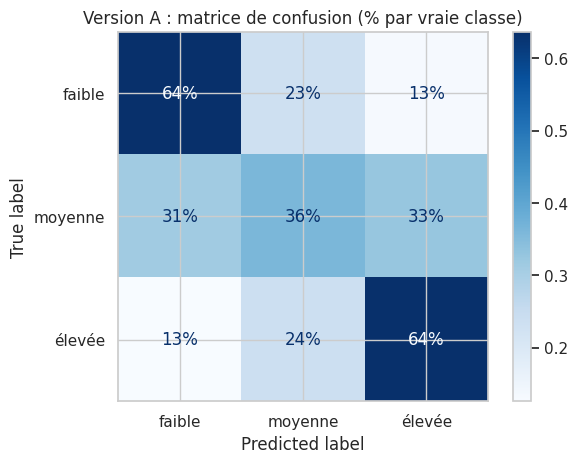

❌ Objectif non atteint : accuracy = 54.5% (< 60 %)


In [ ]:
evaluer("A", modele_A, X_train_A, X_test_A)

**Résultats de la version A (test) :**
- On voit : accuracy **54,5 %** (fourchette à 95 % : environ 53,8 à 55,4 %), donc **sous l'objectif de 60 %**. Précision macro **0,54**, F1 macro **0,54**.
- Les classes « faible » et « élevée » sont assez bien reconnues (précision 0,59 et 0,58 ; rappel 0,64 chacune). La classe « moyenne » est la plus faible (précision 0,43, rappel 0,36).
- **Rappel « élevée » = 64 %** : sur 100 patients vraiment à polymédication élevée, le modèle en retrouve environ 64. C'est la mesure clé pour la pharmacie.
- Ça veut dire : le modèle fait environ **20 points mieux que le hasard** (33 %), mais pas assez pour le critère de 60 %.

**Comment lire la matrice :** les erreurs se font surtout entre classes **voisines** (faible ↔ moyenne, moyenne ↔ élevée). C'est normal : un patient à 11 ou 12 médicaments est presque pareil mais tombe dans deux groupes différents. Se tromper entre « faible » et « élevée » serait bien plus grave.

**Si l'accuracy est sous 60 % :** on ne règle **jamais** le modèle avec le test pour forcer le score, ce serait de la triche. On explique les limites (Partie 8).

## 4.6 A-t-il appris par cœur ? (sur-apprentissage)
**Pourquoi ?** Un modèle peut être excellent sur les patients qu'il a déjà vus et mauvais sur les nouveaux : c'est l'**overfitting**.

**Comment ?** On compare l'accuracy sur le train et sur le test.
- Écart petit (moins de 5 points) : le modèle généralise bien.
- Écart grand : il a appris par cœur.

In [ ]:
def verifier_surapprentissage(nom_version):
    r = resultats[nom_version]
    print(f"Train : {r['accuracy_train']:.3f}   |   Test : {r['accuracy']:.3f}   |   Écart : {r['ecart']:.3f}")
    if r['ecart'] > 0.10:
        print("⚠️ Écart important : sur-apprentissage.")
    elif r['ecart'] > 0.05:
        print("🟡 Léger sur-apprentissage.")
    else:
        print("✅ Le modèle généralise bien.")

verifier_surapprentissage("A")

Train : 0.546   |   Test : 0.545   |   Écart : 0.001
✅ Le modèle généralise bien.


- On voit : train **54,6 %** et test **54,5 %**, soit un écart d'environ **0,1 point**.
- Ça veut dire : le modèle **n'apprend pas par cœur**. Il est mauvais partout de la même façon : il est limité par **l'information disponible à l'admission**, pas par l'algorithme (on dit qu'il a un biais élevé). Régler encore plus finement ne ferait pas franchir 60 %.

## 4.7 Qu'est-ce qui compte pour le modèle ?
**Pourquoi ?** Pour expliquer le modèle au médecin et à la pharmacie : quelles informations pèsent le plus dans la prédiction ?

**À faire :** compare ce graphique avec le graphique ANOVA de la partie 3.

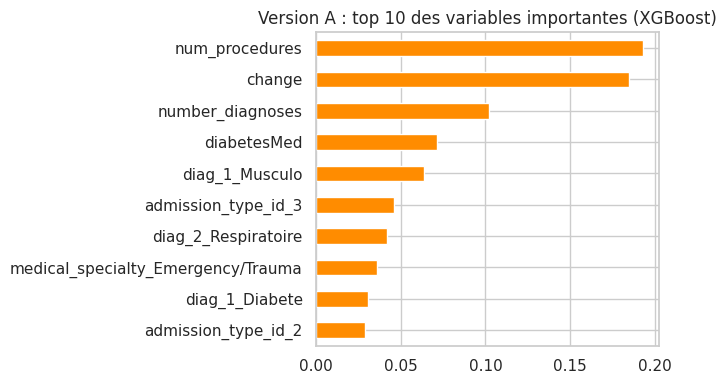

In [ ]:
importance_A = pd.Series(modele_A.feature_importances_, index=X_train_A.columns)
importance_A.sort_values().tail(10).plot(kind='barh', figsize=(7,4), color="darkorange")
plt.title("Version A : top 10 des variables importantes (XGBoost)"); plt.tight_layout(); plt.show()

- On voit : en tête `num_procedures`, `change`, `number_diagnoses`, `diabetesMed`, puis `diag_1_Musculo`.
- Ça veut dire : les mêmes variables que dans l'ANOVA (partie 3). Les deux méthodes racontent la même histoire : **plus d'actes et de diagnostics, et un traitement modifié, signifient plus de médicaments**.
- **Limite à noter :** `change` et `diabetesMed` (changement de traitement, médicament pour le diabète) ne sont pas toujours connus dès l'admission. La version A est donc « à l'admission » surtout par rapport à la version B, pas de façon absolue.

# PARTIE 5 : Version B, le modèle « après le séjour »
*(CRISP-DM : phase 4 Modélisation + phase 5 Évaluation)*

## 5.1 Pourquoi une version B ?

**Le constat (version A) :** avec seulement les informations tôt dans le séjour, le modèle plafonne autour de 53-55 %. Il n'apprend pas par cœur (écart train/test petit). Le problème vient donc des **données**, pas de l'algorithme : il manque une information importante.

**L'information qui manque :** la partie 2.4 l'a montré : plus un patient prend de médicaments, plus son séjour est long. De même, plus on fait d'analyses de labo, plus il y a de soins. La **durée du séjour** (`time_in_hospital`) et le **nombre d'analyses** (`num_lab_procedures`) sont donc de bons indices.

**Le prix à payer :** ces deux informations ne sont connues qu'à la **fin** du séjour.

| | Version A | Version B |
|---|---|---|
| Variables | 20 (ANOVA) | toutes (environ 86), dont les 2 nouvelles |
| Moment d'utilisation | À l'admission | À la sortie du patient |
| Rôle pour la pharmacie | Prévenir dès l'arrivée | Contrôler les ordonnances avant la sortie |

⚠️ **Ce n'est pas de la triche** : ces deux variables ne contiennent **pas** la réponse. Elles sont seulement liées à la cible. Mais **l'objectif métier change** : B ne peut plus prévenir la pharmacie « dès l'admission ». Il faut le dire clairement à la prof.

## 5.2 Pourquoi garder toutes les variables (et pas seulement 20) ?
Pour la version B, au lieu d'imposer « 20 variables », on le **vérifie** par validation croisée **sur le train** (le test n'est pas touché).
- Option 1 : les 20 variables de l'ANOVA + les 2 nouvelles
- Option 2 : toutes les variables

In [ ]:
modele_ref = XGBClassifier(n_estimators=200, max_depth=5, learning_rate=0.05, subsample=0.7,
                           colsample_bytree=0.7, eval_metric='mlogloss', random_state=42, n_jobs=-1)
options = {
    "20 variables ANOVA + 2 nouvelles": feat_A + vars_fin_sejour,
    "Toutes les variables":             list(X_train_B.columns),
}
lignes = []
for nom, colonnes in options.items():
    r = cross_validate(modele_ref, X_train_B[colonnes], y_train, cv=cv, scoring=['accuracy','f1_macro'])
    lignes.append({"Option": nom, "Nb variables": len(colonnes),
                   "Accuracy (CV)": r['test_accuracy'].mean(), "F1 macro (CV)": r['test_f1_macro'].mean()})
pd.DataFrame(lignes).round(3)

,Option,Nb variables,Accuracy (CV),F1 macro (CV)
0,20 variables ANOVA + 2 nouvelles,22,0.584,0.580
1,Toutes les variables,86,0.599,0.594


- On voit : garder **toutes** les variables donne **59,9 %** en validation croisée, contre **58,4 %** avec seulement 22 variables.
- Ça veut dire : en version B, limiter à 20 variables jetterait de l'information utile. XGBoost sait ignorer ce qui ne sert pas, grâce à sa régularisation et à `colsample_bytree`.
- **Décision :** version B = toutes les variables.

## 5.3 Vérifier que le choix est utile
Même contrôle qu'en 4.3 (Dummy, régression logistique, XGBoost de base), cette fois avec toutes les variables.

In [ ]:
comparer_references(X_train_B)

,Modèle,Accuracy (CV),F1 macro (CV)
0,Dummy (hasard),0.337,0.337
1,Régression logistique,0.585,0.579
2,XGBoost (réglages de base),0.599,0.594


- On voit : le Dummy est à 33,7 %, la régression logistique à **58,5 %** et XGBoost à **59,9 %**.
- Ça veut dire : avec les deux nouvelles variables, tout le monde gagne environ **6 points** (de 52-53 % à 58-60 %). XGBoost garde une petite avance sur la régression logistique (1,4 point).

## 5.4 Régler XGBoost pour la version B (tuning)
Même méthode qu'en 4.4 : `RandomizedSearchCV` sur le **train** uniquement, noté par le F1 macro. Comme B a plus de variables, on propose aussi des valeurs plus basses pour `colsample_bytree`.

⏱️ Cette cellule prend quelques minutes (plus longue que pour A).

In [ ]:
grille_B = {
    "n_estimators":     [200, 300, 500],
    "max_depth":        [4, 5, 6],
    "learning_rate":    [0.03, 0.05, 0.1],
    "subsample":        [0.7, 0.85, 1.0],
    "colsample_bytree": [0.5, 0.7, 0.85],
}
recherche_B = RandomizedSearchCV(
    XGBClassifier(eval_metric='mlogloss', random_state=42, n_jobs=-1),
    grille_B, n_iter=8, cv=3, scoring='f1_macro', random_state=42)
recherche_B.fit(X_train_B, y_train)

modele_B = recherche_B.best_estimator_
print("Meilleurs réglages :", recherche_B.best_params_)
print("F1 macro (CV) avec ces réglages : %.3f" % recherche_B.best_score_)

Meilleurs réglages : {'subsample': 0.7, 'n_estimators': 500, 'max_depth': 6, 'learning_rate': 0.03, 'colsample_bytree': 0.5}
F1 macro (CV) avec ces réglages : 0.598


## 5.5 Évaluation finale de la version B (phase 5)
Même examen que pour A : le test, **une seule fois**.

Accuracy : 0.609   |   F1 macro : 0.606

              precision    recall  f1-score   support

      faible      0.656     0.684     0.670      4656
     moyenne      0.482     0.448     0.464      4640
      élevée      0.674     0.692     0.683      4698

    accuracy                          0.609     13994
   macro avg      0.604     0.608     0.606     13994
weighted avg      0.604     0.609     0.606     13994



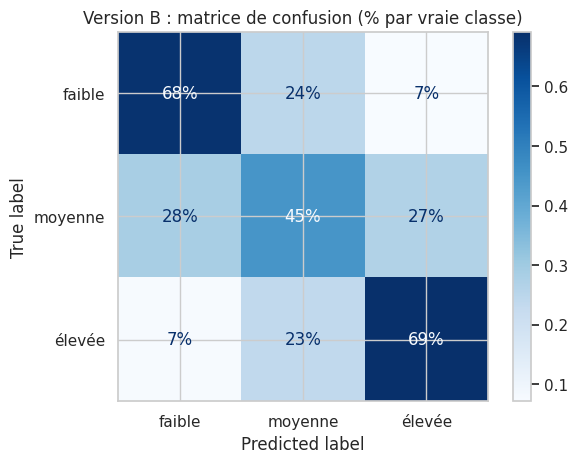

✅ Objectif atteint : accuracy = 60.9% (≥ 60 %)


In [ ]:
evaluer("B", modele_B, X_train_B, X_test_B)

**Résultats de la version B (test) :**
- On voit : accuracy **60,9 %**, donc **au-dessus de l'objectif de 60 %** (de justesse : voir la fourchette en 7.5). Précision macro **0,60**, F1 macro **0,61**.
- Classe « élevée » : précision **0,67** et rappel **0,69**. Classe « faible » : 0,66 et 0,68. La classe « moyenne » reste la plus faible (0,48 et 0,45), mais elle a progressé.
- Ça veut dire : savoir **combien de temps le patient est resté** aide nettement à deviner son nombre de médicaments (+6 points d'accuracy par rapport à A).

## 5.6 A-t-il appris par cœur ?
B a plus de variables et des arbres plus profonds : on re-vérifie. Un écart de moins de 5 points est acceptable.

In [ ]:
verifier_surapprentissage("B")

Train : 0.651   |   Test : 0.609   |   Écart : 0.043
✅ Le modèle généralise bien.


- On voit : train **65,1 %** et test **60,9 %**, soit un écart d'environ **4,3 points**.
- Ça veut dire : B apprend un peu plus par cœur que A (écart 0,1 point), c'est normal avec 86 variables et des arbres plus profonds. L'écart reste **sous 5 points** : acceptable, mais à surveiller.

## 5.7 Qu'est-ce qui compte pour le modèle B ?

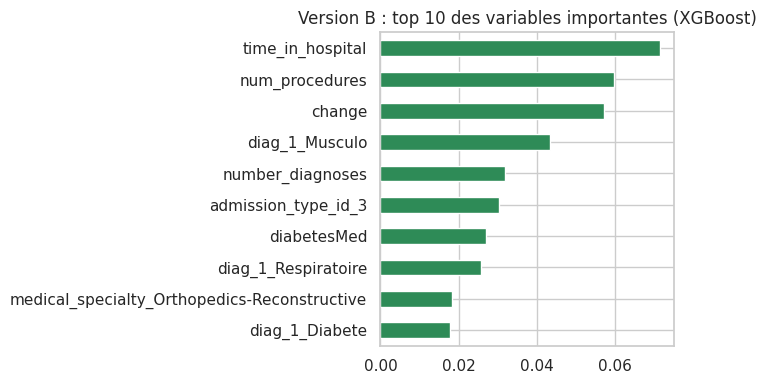

In [ ]:
importance_B = pd.Series(modele_B.feature_importances_, index=X_train_B.columns)
importance_B.sort_values().tail(10).plot(kind='barh', figsize=(7,4), color="seagreen")
plt.title("Version B : top 10 des variables importantes (XGBoost)"); plt.tight_layout(); plt.show()

- On voit : en tête `time_in_hospital`, puis `num_procedures`, `change`, `diag_1_Musculo` et `number_diagnoses`.
- Ça veut dire : la **durée du séjour** devient la variable la plus importante, ce qui explique le gain de la version B. `num_lab_procedures` pèse moins que prévu : la durée du séjour est le vrai apport.

# PARTIE 6 : Le déséquilibre des classes et SMOTE
*(CRISP-DM : phase 4, modélisation)*

## 6.1 C'est quoi le problème du déséquilibre ?
Si une classe est très rare (par exemple 5 % des patients), le modèle peut « tricher » en répondant toujours la classe fréquente : il a 95 % de bonnes réponses mais ne trouve jamais la classe rare. Pour éviter ça, on peut **SMOTE** : créer des patients **artificiels** de la classe rare, en les « mélangeant » avec leurs voisins réels.

**Règle d'or :** SMOTE s'applique **uniquement sur le train**, jamais sur le test. Et en validation croisée, on le met **dans** la boucle (sinon des patients artificiels fuiteraient dans la partie de validation).

## 6.2 Notre cible est-elle déséquilibrée ?

In [ ]:
print("Patients par classe dans le train (avant SMOTE) :")
print(y_train.value_counts().sort_index().rename({0:"faible",1:"moyenne",2:"élevée"}))

X_smote, y_smote = SMOTE(random_state=42).fit_resample(X_train_A, y_train)
print("\nAprès SMOTE :")
print(y_smote.value_counts().sort_index().rename({0:"faible",1:"moyenne",2:"élevée"}))
print(f"\nSMOTE ajoute seulement {len(y_smote) - len(y_train)} patients artificiels sur {len(y_train)}.")

Patients par classe dans le train (avant SMOTE) :
polymed_group
faible     18855
moyenne    18496
élevée     18625
Name: count, dtype: int64

Après SMOTE :
polymed_group
faible     18855
moyenne    18855
élevée     18855
Name: count, dtype: int64

SMOTE ajoute seulement 589 patients artificiels sur 55976.


- On voit : les 3 classes ont presque le même nombre de patients. SMOTE n'ajoute que **589 patients artificiels** sur près de 56 000 (environ 1 %).
- Ça veut dire : **il n'y a pas de déséquilibre à corriger** sur notre cible.

## 6.3 Test honnête : SMOTE améliore-t-il le résultat ?
Pour répondre proprement à la prof, on compare **avec** et **sans** SMOTE, par validation croisée **sur le train** (le test reste intact), pour les versions A et B, avec les réglages trouvés plus haut.

In [ ]:
def comparer_smote(params, X_tr, nom):
    sans = XGBClassifier(**params, eval_metric='mlogloss', random_state=42, n_jobs=-1)
    avec = ImbPipeline([("smote", SMOTE(random_state=42)),
                        ("xgb", XGBClassifier(**params, eval_metric='mlogloss', random_state=42, n_jobs=-1))])
    lignes = []
    for libelle, m in [("Sans SMOTE", sans), ("Avec SMOTE", avec)]:
        r = cross_validate(m, X_tr, y_train, cv=cv, scoring=['accuracy','f1_macro'])
        lignes.append({"Version": nom, "Cas": libelle,
                       "Accuracy (CV)": r['test_accuracy'].mean(), "F1 macro (CV)": r['test_f1_macro'].mean()})
    return pd.DataFrame(lignes)

tableau_smote = pd.concat([comparer_smote(recherche_A.best_params_, X_train_A, "A"),
                           comparer_smote(recherche_B.best_params_, X_train_B, "B")])
tableau_smote.round(3)

,Version,Cas,Accuracy (CV),F1 macro (CV)
0,A,Sans SMOTE,0.536,0.529
1,A,Avec SMOTE,0.536,0.530
0,B,Sans SMOTE,0.602,0.598
1,B,Avec SMOTE,0.600,0.597


- On voit : avec ou sans SMOTE, les scores sont **identiques à 0,001 près** (A : 53,6 % dans les deux cas ; B : 60,2 % contre 60,1 %).
- Ça veut dire : SMOTE **n'apporte rien** ici, ce qui est logique puisque les classes sont déjà équilibrées.
- **Décision :** on ne l'utilise pas dans les modèles finaux. Ce tableau est la preuve à montrer à la prof : « J'ai essayé SMOTE, il n'améliore pas le résultat, car ma cible n'est pas déséquilibrée. »
- **La vraie faiblesse** du modèle n'est pas un déséquilibre : c'est la classe « moyenne », coincée entre deux classes voisines (un patient à 11 ou 12 médicaments est presque identique, mais tombe dans deux groupes différents).
- *Petite remarque technique :* SMOTE classique crée des valeurs décimales dans des colonnes 0/1 (un « demi-patient »). Une variante, SMOTENC, gère mieux ce cas. Ça ne change pas la conclusion ici.

# PARTIE 7 : Comparaison de la version A et de la version B
*(CRISP-DM : phase 5, évaluation)*

## 7.1 Le tableau de comparaison (sur le test)

In [ ]:
lignes = [("Accuracy (objectif ≥ 60 %)", "accuracy"), ("Précision macro", "precision_macro"),
          ("Rappel macro", "rappel_macro"), ("F1 macro", "f1_macro"),
          ("Précision classe « élevée »", "precision_elevee"), ("Rappel classe « élevée »", "rappel_elevee"),
          ("Accuracy sur le train", "accuracy_train"), ("Écart train - test", "ecart")]
comparaison = pd.DataFrame({
    "Version A (admission)":    [resultats["A"][k] for _, k in lignes],
    "Version B (après séjour)": [resultats["B"][k] for _, k in lignes]},
    index=[nom for nom, _ in lignes]).round(3)

comparaison.loc["Variables utilisées"] = [X_train_A.shape[1], X_train_B.shape[1]]
comparaison.loc["Objectif ≥ 60 % atteint ?"] = ["Oui ✅" if resultats[v]["accuracy"] >= 0.60 else "Non ❌" for v in ("A","B")]
comparaison.loc["Utilisable à l'admission ?"] = ["Oui", "Non (fin de séjour)"]
comparaison

,Version A (admission),Version B (après séjour)
Accuracy (objectif ≥ 60 %),0.545,0.609
Précision macro,0.536,0.604
Rappel macro,0.545,0.608
F1 macro,0.539,0.606
Précision classe « élevée »,0.584,0.674
Rappel classe « élevée »,0.637,0.692
Accuracy sur le train,0.546,0.651
Écart train - test,0.001,0.043
Variables utilisées,20.0,86.0
Objectif ≥ 60 % atteint ?,Non ❌,Oui ✅


**Comment lire le tableau :**
- B gagne sur **toutes** les mesures : accuracy (+6,4 points), précision macro, rappel macro, F1 macro, et la classe « élevée » (rappel 69 % contre 64 %).
- B est la seule version qui atteint **60 %**.
- B a un écart train/test plus grand (4,3 points contre 0,1) : il apprend un peu plus par cœur, mais reste dans la zone acceptable.
- **Le piège :** B n'est utilisable qu'**à la fin du séjour**.

## 7.2 Les mêmes résultats en graphique

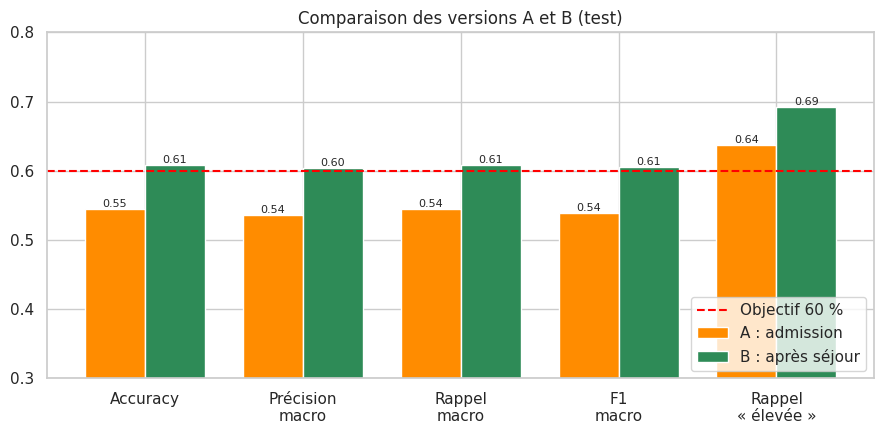

In [ ]:
metriques = [("Accuracy","accuracy"), ("Précision\nmacro","precision_macro"), ("Rappel\nmacro","rappel_macro"),
             ("F1\nmacro","f1_macro"), ("Rappel\n« élevée »","rappel_elevee")]
x = np.arange(len(metriques)); larg = 0.38
fig, ax = plt.subplots(figsize=(9,4.5))
barres_A = ax.bar(x - larg/2, [resultats["A"][k] for _, k in metriques], larg, label="A : admission", color="darkorange")
barres_B = ax.bar(x + larg/2, [resultats["B"][k] for _, k in metriques], larg, label="B : après séjour", color="seagreen")
ax.axhline(0.60, color="red", linestyle="--", label="Objectif 60 %")
ax.set_xticks(x); ax.set_xticklabels([n for n, _ in metriques]); ax.set_ylim(0.3, 0.8)
ax.bar_label(barres_A, fmt="%.2f", fontsize=8); ax.bar_label(barres_B, fmt="%.2f", fontsize=8)
ax.set_title("Comparaison des versions A et B (test)"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

## 7.3 Classe par classe
**Pourquoi ?** Une bonne accuracy peut cacher une classe mal reconnue. On regarde donc la précision, le rappel et le F1 de chaque classe.

In [ ]:
def par_classe(version):
    p = precision_score(y_test, resultats[version]["y_pred"], average=None)
    r = recall_score(y_test, resultats[version]["y_pred"], average=None)
    f = f1_score(y_test, resultats[version]["y_pred"], average=None)
    return pd.DataFrame({(version, "précision"): p, (version, "rappel"): r, (version, "F1"): f}, index=noms_classes)

pd.concat([par_classe("A"), par_classe("B")], axis=1).round(3)

A                       B              
        précision rappel     F1 précision rappel     F1
faible      0.592  0.637  0.614     0.656  0.684  0.670
moyenne     0.433  0.361  0.393     0.482  0.448  0.464
élevée      0.584  0.637  0.609     0.674  0.692  0.683

- On voit : la classe « moyenne » est la plus difficile dans les deux versions (F1 de 0,39 en A, 0,46 en B). Les classes « faible » et « élevée » sont bien mieux reconnues (F1 entre 0,61 et 0,68).
- Ça veut dire : le modèle est bon pour repérer les **extrêmes**, qui sont les cas utiles à la pharmacie. La faiblesse sur « moyenne » est normale : c'est une classe coincée entre deux autres.

## 7.4 Les deux matrices de confusion côte à côte

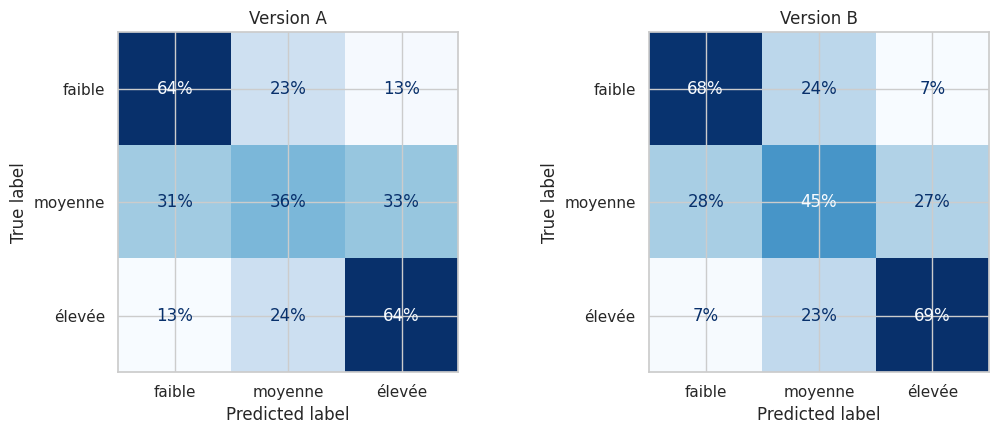

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11,4.5))
for a, v in zip(ax, ["A", "B"]):
    ConfusionMatrixDisplay.from_predictions(y_test, resultats[v]["y_pred"], display_labels=noms_classes,
                                            normalize='true', values_format='.0%', cmap="Blues", ax=a, colorbar=False)
    a.set_title(f"Version {v}")
plt.tight_layout(); plt.show()

- On voit : la diagonale (les bonnes réponses) est plus foncée en B qu'en A.
- Les erreurs les plus graves sont celles entre « faible » et « élevée » : environ **13 %** des patients en A (faible prédit élevée : 13 %, et élevée prédit faible : 13 %), et seulement **7 %** en B.
- La classe « moyenne » est confondue avec ses voisines : environ 31 % et 33 % de ses patients en A, 28 % et 27 % en B.
- Ça veut dire : B se trompe moins, et surtout fait **presque deux fois moins** d'erreurs graves. La plupart des erreurs restent entre classes voisines.

## 7.5 Le résultat est-il solide ? (fourchette à 95 %)
Un test de 14 000 patients donne une accuracy « à quelques dixièmes près ». On calcule une **fourchette** : si elle touche 60 %, le résultat est **limite**.

In [ ]:
for v in ["A", "B"]:
    bas, haut = intervalle_accuracy(y_test, resultats[v]["y_pred"])
    resultats[v]["ic"] = (bas, haut)
    print(f"Version {v} : accuracy = {resultats[v]['accuracy']:.1%}   fourchette à 95 % = [{bas:.1%} ; {haut:.1%}]")

Version A : accuracy = 54.5%   fourchette à 95 % = [53.8% ; 55.4%]
Version B : accuracy = 60.9%   fourchette à 95 % = [60.0% ; 61.6%]


- On voit : la fourchette de la version B va d'environ **60,0 % à 61,6 %**. Sa borne basse touche exactement 60 %.
- Ça veut dire : B atteint le critère, mais **de justesse**. Il ne faut pas dire « B est largement au-dessus de 60 % ». Une phrase honnête : « B obtient environ 61 % sur le test (60 à 62 %), et 60 % en validation croisée sur le train ».
- A est clairement sous 60 % (sa borne haute est d'environ 55 %).

# PARTIE 8 : Évaluation finale et décision
*(CRISP-DM : phase 5, évaluation)*

## 8.1 Le bilan chiffré

In [ ]:
print("=" * 62)
for v, nom in [("A", "Version A (admission)"), ("B", "Version B (après séjour)")]:
    r = resultats[v]
    print(f"{nom}")
    print(f"  Accuracy        : {r['accuracy']:.1%}   (fourchette 95 % : {r['ic'][0]:.1%} à {r['ic'][1]:.1%})")
    print(f"  Précision macro : {r['precision_macro']:.3f}   |   F1 macro : {r['f1_macro']:.3f}")
    print(f"  Rappel « élevée » : {r['rappel_elevee']:.1%}   |   Écart train/test : {r['ecart']:.3f}")
    print(f"  Objectif ≥ 60 % : {'ATTEINT ✅' if r['accuracy'] >= 0.60 else 'NON ATTEINT ❌'}")
    print("=" * 62)

Version A (admission)
  Accuracy        : 54.5%   (fourchette 95 % : 53.8% à 55.4%)
  Précision macro : 0.536   |   F1 macro : 0.539
  Rappel « élevée » : 63.7%   |   Écart train/test : 0.001
  Objectif ≥ 60 % : NON ATTEINT ❌
Version B (après séjour)
  Accuracy        : 60.9%   (fourchette 95 % : 60.0% à 61.6%)
  Précision macro : 0.604   |   F1 macro : 0.606
  Rappel « élevée » : 69.2%   |   Écart train/test : 0.043
  Objectif ≥ 60 % : ATTEINT ✅



## 8.2 A-t-on atteint les critères de réussite ?

| Critère | Version A (admission) | Version B (après séjour) |
|---|---|---|
| Accuracy ≥ 60 % | ❌ 54,5 % | ✅ 60,9 % (de justesse) |
| Bonne précision | 🟡 0,54 en moyenne | ✅ 0,60 en moyenne (0,67 pour « élevée ») |
| Bon rappel pour « élevée » | 🟡 64 % | ✅ 69 % |
| Pas de sur-apprentissage | ✅ écart 0,1 point | ✅ écart 4,3 points (< 5) |
| Utilisable dès l'admission | ✅ oui | ❌ non, à la sortie |
| Classes équilibrées (SMOTE inutile) | ✅ prouvé en Partie 6 | ✅ prouvé en Partie 6 |

## 8.3 Les limites à connaître
1. **A plafonne à environ 54-55 %.** L'écart train/test est minuscule : le modèle ne manque pas de puissance, il manque d'**information** à l'admission.
2. **B atteint 60 % de justesse** (fourchette 60,0 à 61,6 %). Si on change le découpage train/test, on peut être à 60 ou 61 %. Les chiffres peuvent aussi bouger de quelques dixièmes selon la version de XGBoost.
3. **B change l'objectif métier** : il n'agit plus « dès l'admission » mais « avant la sortie ».
4. **La classe « moyenne »** reste difficile (F1 entre 0,39 et 0,46), car elle est coincée entre deux classes voisines et la cible est un nombre coupé en 3.
5. **Association, pas cause** : un patient plus malade a plus de médicaments et reste plus longtemps. Le modèle utilise cette association, il ne prouve pas de cause.
6. Quelques variables de A (`change`, `diabetesMed`) ne sont pas toujours connues dès l'arrivée.

## 8.4 La décision (CRISP-DM : « on déploie, on améliore ou on refait ? »)

> **Objectif métier atteint ?**
> - Version A : **non**. Elle respecte le moment (admission) mais ne passe pas le critère de 60 %.
> - Version B : **oui pour le critère de la prof (≥ 60 %) et pour la précision**, avec la réserve du moment d'utilisation.

**Décision proposée : passer au déploiement avec la version B**, présentée honnêtement comme un **modèle de contrôle avant la sortie du patient** : « avant la sortie, la pharmacie reçoit la liste des patients dont la polymédication est probablement élevée, pour revérifier leurs ordonnances. » La version A est conservée dans le rapport comme **modèle de référence à l'admission** (il montre la limite des données).

**À valider avec la prof :** cette reformulation de l'objectif (« à l'admission » devient « avant la sortie »).

**Ce qu'il faut dire à l'oral, en une phrase :** *« Avec l'information disponible à l'admission, on plafonne à 54,5 %. En ajoutant la durée du séjour, on passe à 60,9 %, ce qui atteint le critère, mais le modèle ne sert alors qu'à la fin du séjour. »*

## 8.5 Ce qui a été corrigé par rapport à l'ancienne version
| Problème | Correction |
|---|---|
| Plafond (`clip`) et seuils de la cible calculés **avant** le découpage (petite fuite) | Découpage en premier, puis plafond, seuils, top spécialités et scaler calculés **sur le train** seulement |
| Version B absente | Partie 5 ajoutée (modèle, réglage, évaluation, sur-apprentissage) |
| Pas de réponse sur le déséquilibre | Partie 6 : proportions, SMOTE sur le train, comparaison chiffrée |
| Pas de comparaison A / B | Partie 7 : tableau, graphique, classe par classe, matrices, fourchette à 95 % |
| Pas de conclusion d'évaluation | Partie 8 : critères, limites, décision |
| Noms de colonnes nettoyés tard | Nettoyage fait dès l'encodage, pour A et B |
| Texte parlant de modèles non utilisés | Notebook centré sur XGBoost, avec références Dummy et régression logistique |

## 8.6 La suite : le déploiement (phase 6)
Ce notebook s'arrête à l'évaluation, comme demandé. Pour le déploiement avec la version B, il faudra sauvegarder dans un seul objet : le modèle `modele_B`, la liste des colonnes, le `scaler`, le plafond `cap`, les seuils (`seuil1`, `seuil2`), la liste `top_specialites` et les fonctions de préparation (`famille`, `encoder`). Un nouveau patient doit subir **exactement** la même préparation que ceux de l'entraînement.
